=== FINAL MODEL COMPARISON SUMMARY ===
              Model  Precision (High Quality)  Recall (High Quality)  F1-Score  ROC-AUC  False Positives (FP)  False Negatives (FN)
      Random Forest                  0.706122               0.675781  0.690619 0.909513                    72                    83
            XGBoost                  0.643382               0.683594  0.662879 0.902333                    97                    81
      Decision Tree                  0.411647               0.800781  0.543767 0.811718                   293                    51
Logistic Regression                  0.382470               0.750000  0.506596 0.801904                   310                    64


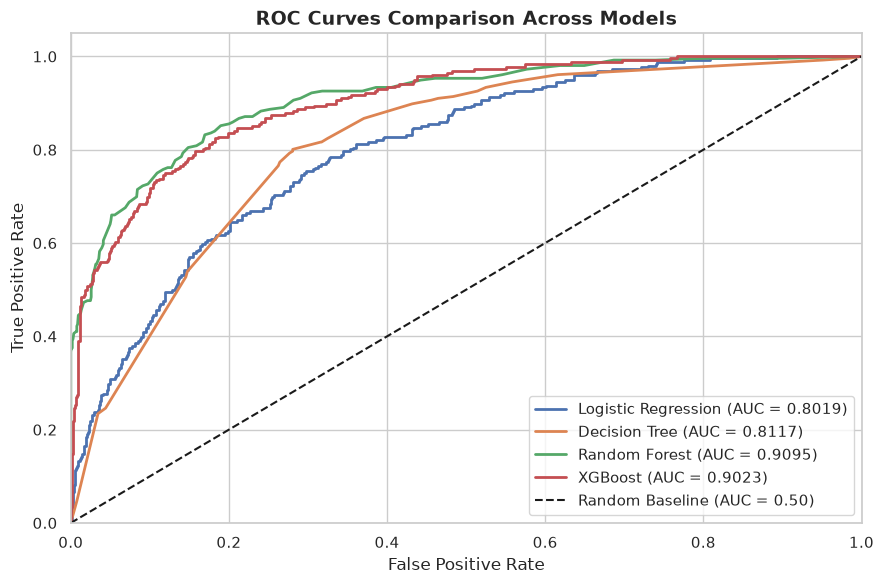

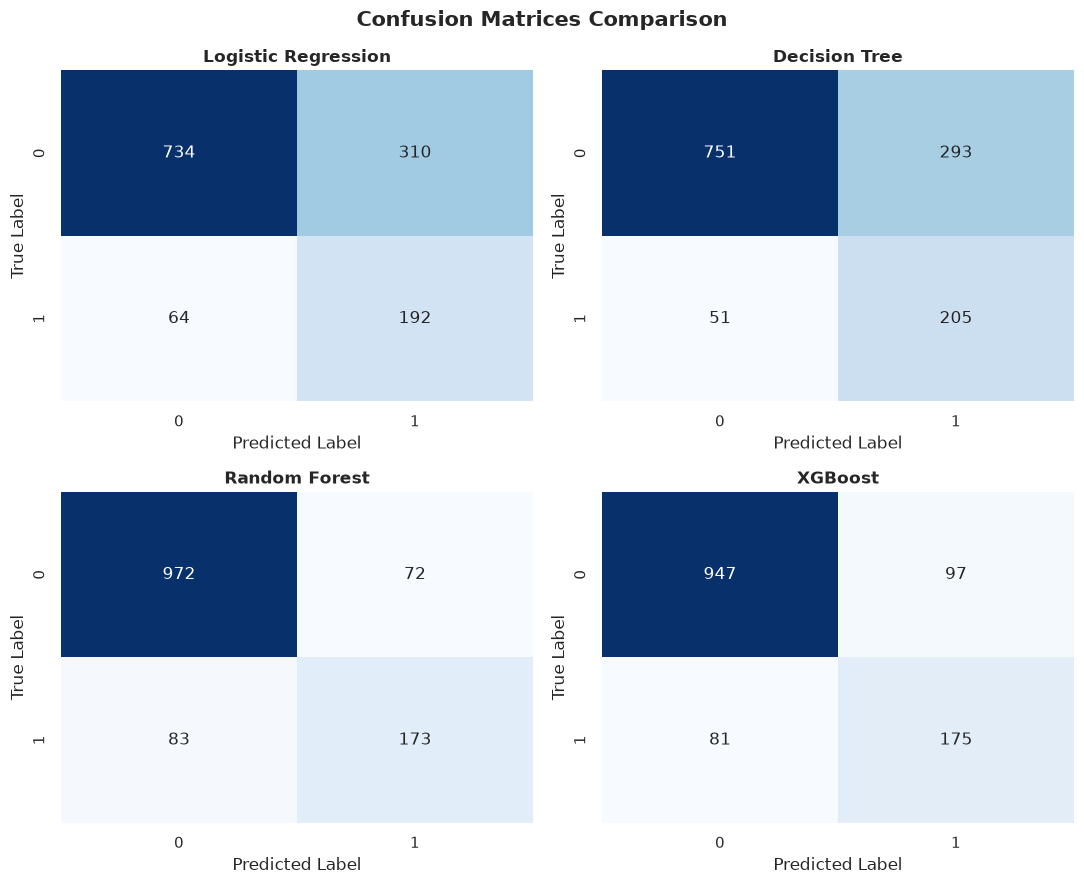

In [1]:

# 1. Imports and Setup
import sys
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    f1_score,
    precision_score,
    recall_score
)

# Set plot style
sns.set_theme(style="whitegrid")
plt.rcParams["font.sans-serif"] = "DejaVu Sans"

# ------------------------------------------
# 2. Load & Prepare Data
# ------------------------------------------
# Load combined dataset
data_path = os.path.join("..", "data", "processed", "wine_quality_combined.csv")
df_wine = pd.read_csv(data_path)

# Target creation and encoding
df_wine['quality_label'] = (df_wine['quality'] >= 7).astype(int)
df_wine['type_code'] = (df_wine['type'] == 'white').astype(int)

# Separate Features (X) and Target (y)
X = df_wine.drop(columns=['quality', 'quality_label', 'type'])
y = df_wine['quality_label']

# Stratified Train-Test Split (80/20)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Feature Scaling (for models sensitive to scale like Logistic Regression)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Calculate scale_pos_weight for XGBoost imbalance handling
scale_pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)

# ------------------------------------------
# 3. Model Initialization & Dictionary
# ------------------------------------------
models = {
    "Logistic Regression": {
        "model": LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42),
        "use_scaled": True
    },
    "Decision Tree": {
        "model": DecisionTreeClassifier(max_depth=5, class_weight='balanced', random_state=42),
        "use_scaled": False
    },
    "Random Forest": {
        "model": RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42),
        "use_scaled": False
    },
    "XGBoost": {
        "model": XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss'),
        "use_scaled": False
    }
}

# ------------------------------------------
# 4. Model Training & Evaluation Loop
# ------------------------------------------
results = []
roc_data = {}

for name, config in models.items():
    clf = config["model"]
    X_tr = X_train_scaled if config["use_scaled"] else X_train
    X_te = X_test_scaled if config["use_scaled"] else X_test
    
    # Train model
    clf.fit(X_tr, y_train)
    
    # Predictions
    y_pred = clf.predict(X_te)
    y_proba = clf.predict_proba(X_te)[:, 1]
    
    # Store ROC curve points
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    roc_auc = roc_auc_score(y_test, y_proba)
    roc_data[name] = (fpr, tpr, roc_auc)
    
    # Calculate metrics
    cm = confusion_matrix(y_test, y_pred)
    results.append({
        "Model": name,
        "Precision (High Quality)": precision_score(y_test, y_pred),
        "Recall (High Quality)": recall_score(y_test, y_pred),
        "F1-Score": f1_score(y_test, y_pred),
        "ROC-AUC": roc_auc,
        "False Positives (FP)": cm[0, 1],
        "False Negatives (FN)": cm[1, 0]
    })

# Convert summary into a DataFrame
df_summary = pd.DataFrame(results).sort_values(by="ROC-AUC", ascending=False)

print("=== FINAL MODEL COMPARISON SUMMARY ===")
print(df_summary.to_string(index=False))

# ------------------------------------------
# 5. Visualizations
# ------------------------------------------

# A. Overlaid ROC Curves Plot
plt.figure(figsize=(9, 6))
for name, (fpr, tpr, auc_score) in roc_data.items():
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc_score:.4f})")

plt.plot([0, 1], [0, 1], 'k--', label="Random Baseline (AUC = 0.50)")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves Comparison Across Models", fontsize=14, fontweight='bold')
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

# B. Side-by-Side Confusion Matrices (2x2 Grid)
fig, axes = plt.subplots(2, 2, figsize=(11, 9))
axes = axes.flatten()

for idx, (name, config) in enumerate(models.items()):
    clf = config["model"]
    X_te = X_test_scaled if config["use_scaled"] else X_test
    y_pred = clf.predict(X_te)
    cm = confusion_matrix(y_test, y_pred)
    
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[idx], cbar=False)
    axes[idx].set_title(f"{name}", fontsize=12, fontweight='bold')
    axes[idx].set_xlabel("Predicted Label")
    axes[idx].set_ylabel("True Label")

plt.suptitle("Confusion Matrices Comparison", fontsize=15, fontweight='bold')
plt.tight_layout()
plt.show()

# ------------------------------------------
# 6. Export Best Model and Scaler (.pkl)
# ------------------------------------------
#models_dir = os.path.join("..", "models")
#os.makedirs(models_dir, exist_ok=True)
#
## Exporting Random Forest as the primary production model
#best_model = models["Random Forest"]["model"]
#
#joblib.dump(best_model, os.path.join(models_dir, "random_forest_model.pkl"))
#joblib.dump(scaler, os.path.join(models_dir, "scaler.pkl"))
#
#print(f"\n[INFO] Best model (Random Forest) and Scaler successfully saved in '{models_dir}/'.")

In [2]:
# ==========================================
# 7. Hyperparameter Tuning (GridSearchCV)
# ==========================================
from sklearn.model_selection import GridSearchCV, StratifiedKFold

# Set up Stratified 5-Fold Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# ------------------------------------------
# A. Random Forest Tuning
# ------------------------------------------
print("=== TUNING RANDOM FOREST ===")

rf_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'max_features': ['sqrt', 'log2']
}

rf_grid = GridSearchCV(
    estimator=RandomForestClassifier(class_weight='balanced', random_state=42),
    param_grid=rf_param_grid,
    scoring='roc_auc',  # Optimize for Area Under ROC Curve
    cv=cv,
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

print(f"Best RF Parameters: {rf_grid.best_params_}")
print(f"Best CV ROC-AUC Score: {rf_grid.best_score_:.4f}")

# Evaluate best RF model on Test Set
best_rf = rf_grid.best_estimator_
y_pred_rf = best_rf.predict(X_test)
y_proba_rf = best_rf.predict_proba(X_test)[:, 1]

print("\n--- Optimized Random Forest Performance ---")
print(classification_report(y_test, y_pred_rf))
print(f"Test Set ROC-AUC Score: {roc_auc_score(y_test, y_proba_rf):.4f}")

# ------------------------------------------
# B. XGBoost Tuning
# ------------------------------------------
print("\n=== TUNING XGBOOST ===")

xgb_param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

xgb_grid = GridSearchCV(
    estimator=XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=42, eval_metric='logloss'),
    param_grid=xgb_param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

xgb_grid.fit(X_train, y_train)

print(f"Best XGBoost Parameters: {xgb_grid.best_params_}")
print(f"Best CV ROC-AUC Score: {xgb_grid.best_score_:.4f}")

# Evaluate best XGBoost model on Test Set
best_xgb = xgb_grid.best_estimator_
y_pred_xgb = best_xgb.predict(X_test)
y_proba_xgb = best_xgb.predict_proba(X_test)[:, 1]

print("\n--- Optimized XGBoost Performance ---")
print(classification_report(y_test, y_pred_xgb))
print(f"Test Set ROC-AUC Score: {roc_auc_score(y_test, y_proba_xgb):.4f}")

=== TUNING RANDOM FOREST ===
Fitting 5 folds for each of 72 candidates, totalling 360 fits
Best RF Parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_split': 2, 'n_estimators': 300}
Best CV ROC-AUC Score: 0.9151

--- Optimized Random Forest Performance ---
              precision    recall  f1-score   support

           0       0.92      0.93      0.93      1044
           1       0.71      0.68      0.70       256

    accuracy                           0.88      1300
   macro avg       0.82      0.81      0.81      1300
weighted avg       0.88      0.88      0.88      1300

Test Set ROC-AUC Score: 0.9138

=== TUNING XGBOOST ===
Fitting 5 folds for each of 108 candidates, totalling 540 fits
Best XGBoost Parameters: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 7, 'n_estimators': 300, 'subsample': 0.8}
Best CV ROC-AUC Score: 0.9032

--- Optimized XGBoost Performance ---
              precision    recall  f1-score   support

           0       0.92    

In [3]:
# ==========================================
# 8. Handling Class Imbalance with SMOTE
# ==========================================
from imblearn.over_sampling import SMOTE
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix

# Initialize SMOTE
smote = SMOTE(random_state=42)

# Apply SMOTE ONLY on the Training set (never on the Test set)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print(f"Original Training Class Distribution: {y_train.value_counts().to_dict()}")
print(f"Resampled Training Class Distribution: {y_train_resampled.value_counts().to_dict()}")

# ------------------------------------------
# Train Random Forest on Resampled Data
# ------------------------------------------
rf_smote = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    max_features='sqrt',
    random_state=42
)

rf_smote.fit(X_train_resampled, y_train_resampled)

# Evaluate on original Test Set
y_pred_smote = rf_smote.predict(X_test)
y_proba_smote = rf_smote.predict_proba(X_test)[:, 1]

print("\n=== RANDOM FOREST PERFORMANCE WITH SMOTE ===")
print(classification_report(y_test, y_pred_smote))
print(f"Test Set ROC-AUC Score: {roc_auc_score(y_test, y_proba_smote):.4f}")

# Confusion Matrix
cm_smote = confusion_matrix(y_test, y_pred_smote)
print("\nConfusion Matrix:")
print(cm_smote)

Original Training Class Distribution: {0: 4176, 1: 1021}
Resampled Training Class Distribution: {0: 4176, 1: 4176}

=== RANDOM FOREST PERFORMANCE WITH SMOTE ===
              precision    recall  f1-score   support

           0       0.93      0.91      0.92      1044
           1       0.66      0.71      0.68       256

    accuracy                           0.87      1300
   macro avg       0.79      0.81      0.80      1300
weighted avg       0.87      0.87      0.87      1300

Test Set ROC-AUC Score: 0.9139

Confusion Matrix:
[[949  95]
 [ 75 181]]


In [4]:
# ==============================================================================
# Advanced Feature Engineering & Separate Models for Red and White Wines
# ==============================================================================
import os
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, precision_score, recall_score, f1_score

# ------------------------------------------------------------------------------
# 1. Load Data & Advanced Feature Engineering
# ------------------------------------------------------------------------------
data_path = os.path.join("..", "data", "processed", "wine_quality_combined.csv")
df_wine = pd.read_csv(data_path)

# Create binary target
df_wine['quality_label'] = (df_wine['quality'] >= 7).astype(int)

# Engineer Domain-Specific Features
df_wine['total_acidity'] = df_wine['fixed_acidity'] + df_wine['volatile_acidity'] + df_wine['citric_acid']
df_wine['bound_sulfur_dioxide'] = df_wine['total_sulfur_dioxide'] - df_wine['free_sulfur_dioxide']
df_wine['sulfur_ratio'] = df_wine['free_sulfur_dioxide'] / (df_wine['total_sulfur_dioxide'] + 1e-5)
df_wine['sugar_alcohol_ratio'] = df_wine['residual_sugar'] / (df_wine['alcohol'] + 1e-5)
df_wine['acid_sugar_ratio'] = df_wine['total_acidity'] / (df_wine['residual_sugar'] + 1e-5)

# Separate Red and White subsets
df_white = df_wine[df_wine['type'] == 'white'].drop(columns=['type', 'quality']).copy()
df_red = df_wine[df_wine['type'] == 'red'].drop(columns=['type', 'quality']).copy()

# ------------------------------------------------------------------------------
# 2. Train-Test Split per Wine Type
# ------------------------------------------------------------------------------
# White Wine Split
X_white = df_white.drop(columns=['quality_label'])
y_white = df_white['quality_label']
X_tr_w, X_te_w, y_tr_w, y_te_w = train_test_split(
    X_white, y_white, test_size=0.2, random_state=42, stratify=y_white
)

# Red Wine Split
X_red = df_red.drop(columns=['quality_label'])
y_red = df_red['quality_label']
X_tr_r, X_te_r, y_tr_r, y_te_r = train_test_split(
    X_red, y_red, test_size=0.2, random_state=42, stratify=y_red
)

# ------------------------------------------------------------------------------
# 3. Model Training (Separate Random Forests)
# ------------------------------------------------------------------------------
rf_white = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42
)

rf_red = RandomForestClassifier(
    n_estimators=300,
    max_depth=None,
    min_samples_split=2,
    max_features='sqrt',
    class_weight='balanced',
    random_state=42
)

rf_white.fit(X_tr_w, y_tr_w)
rf_red.fit(X_tr_r, y_tr_r)

# ------------------------------------------------------------------------------
# 4. Individual Evaluations
# ------------------------------------------------------------------------------
# Predictions White
pred_w = rf_white.predict(X_te_w)
proba_w = rf_white.predict_proba(X_te_w)[:, 1]

# Predictions Red
pred_r = rf_red.predict(X_te_r)
proba_r = rf_red.predict_proba(X_te_r)[:, 1]

print("=== WHITE WINE RANDOM FOREST PERFORMANCE ===")
print(classification_report(y_te_w, pred_w))
print(f"ROC-AUC: {roc_auc_score(y_te_w, proba_w):.4f}\n")

print("=== RED WINE RANDOM FOREST PERFORMANCE ===")
print(classification_report(y_te_r, pred_r))
print(f"ROC-AUC: {roc_auc_score(y_te_r, proba_r):.4f}\n")

# ------------------------------------------------------------------------------
# 5. Combined Overall Evaluation
# ------------------------------------------------------------------------------
y_true_combined = np.concatenate([y_te_w, y_te_r])
y_pred_combined = np.concatenate([pred_w, pred_r])
y_proba_combined = np.concatenate([proba_w, proba_r])

print("==================================================")
print("=== COMBINED SEPARATE MODELS OVERALL PERFORMANCE ===")
print("==================================================")
print(classification_report(y_true_combined, y_pred_combined))
print(f"Combined ROC-AUC Score: {roc_auc_score(y_true_combined, y_proba_combined):.4f}")
print("Confusion Matrix:")
print(confusion_matrix(y_true_combined, y_pred_combined))

=== WHITE WINE RANDOM FOREST PERFORMANCE ===
              precision    recall  f1-score   support

           0       0.94      0.92      0.93       768
           1       0.74      0.78      0.76       212

    accuracy                           0.89       980
   macro avg       0.84      0.85      0.84       980
weighted avg       0.89      0.89      0.89       980

ROC-AUC: 0.9319

=== RED WINE RANDOM FOREST PERFORMANCE ===
              precision    recall  f1-score   support

           0       0.96      0.96      0.96       277
           1       0.74      0.72      0.73        43

    accuracy                           0.93       320
   macro avg       0.85      0.84      0.84       320
weighted avg       0.93      0.93      0.93       320

ROC-AUC: 0.9451

=== COMBINED SEPARATE MODELS OVERALL PERFORMANCE ===
              precision    recall  f1-score   support

           0       0.94      0.93      0.94      1045
           1       0.74      0.77      0.75       255

    acc

In [5]:
# ==============================================================================
# Hyperparameter Tuning for Separate White and Red Wine Random Forest Models
# ==============================================================================
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import numpy as np

# Define Stratified 5-Fold Cross-Validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Parameter Grid for Random Forest
param_grid = {
    'n_estimators': [200, 300, 500],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4],
    'max_features': ['sqrt', 'log2']
}

# ------------------------------------------------------------------------------
# 1. Tuning White Wine Random Forest
# ------------------------------------------------------------------------------
print("=== TUNING WHITE WINE RANDOM FOREST ===")

grid_white = GridSearchCV(
    estimator = RandomForestClassifier(class_weight='balanced', random_state=42),
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_white.fit(X_tr_w, y_tr_w)

best_rf_white = grid_white.best_estimator_
print(f"Best White RF Parameters: {grid_white.best_params_}")
print(f"Best White CV ROC-AUC Score: {grid_white.best_score_:.4f}\n")

# ------------------------------------------------------------------------------
# 2. Tuning Red Wine Random Forest
# ------------------------------------------------------------------------------
print("=== TUNING RED WINE RANDOM FOREST ===")

grid_red = GridSearchCV(
    estimator=RandomForestClassifier(class_weight='balanced', random_state=42),
    param_grid=param_grid,
    scoring='roc_auc',
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_red.fit(X_tr_r, y_tr_r)

best_rf_red = grid_red.best_estimator_
print(f"Best Red RF Parameters: {grid_red.best_params_}")
print(f"Best Red CV ROC-AUC Score: {grid_red.best_score_:.4f}\n")

# ------------------------------------------------------------------------------
# 3. Final Evaluation on Test Sets
# ------------------------------------------------------------------------------
# Predictions for White
pred_w_opt = best_rf_white.predict(X_te_w)
proba_w_opt = best_rf_white.predict_proba(X_te_w)[:, 1]

# Predictions for Red
pred_r_opt = best_rf_red.predict(X_te_r)
proba_r_opt = best_rf_red.predict_proba(X_te_r)[:, 1]

print("=== OPTIMIZED WHITE WINE RF PERFORMANCE ===")
print(classification_report(y_te_w, pred_w_opt))
print(f"ROC-AUC: {roc_auc_score(y_te_w, proba_w_opt):.4f}\n")

print("=== OPTIMIZED RED WINE RF PERFORMANCE ===")
print(classification_report(y_te_r, pred_r_opt))
print(f"ROC-AUC: {roc_auc_score(y_te_r, proba_r_opt):.4f}\n")

# Combined Results
y_true_comb_opt = np.concatenate([y_te_w, y_te_r])
y_pred_comb_opt = np.concatenate([pred_w_opt, pred_r_opt])
y_proba_comb_opt = np.concatenate([proba_w_opt, proba_r_opt])

print("==================================================")
print("=== COMBINED OPTIMIZED SEPARATE MODELS PERFORMANCE ===")
print("==================================================")
print(classification_report(y_true_comb_opt, y_pred_comb_opt))
print(f"Combined ROC-AUC Score: {roc_auc_score(y_true_comb_opt, y_proba_comb_opt):.4f}")
print("Confusion Matrix:")
print(confusion_matrix(y_true_comb_opt, y_pred_comb_opt))

=== TUNING WHITE WINE RANDOM FOREST ===
Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best White RF Parameters: {'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 500}
Best White CV ROC-AUC Score: 0.9029

=== TUNING RED WINE RANDOM FOREST ===
Fitting 5 folds for each of 216 candidates, totalling 1080 fits
Best Red RF Parameters: {'max_depth': 20, 'max_features': 'sqrt', 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 300}
Best Red CV ROC-AUC Score: 0.9038

=== OPTIMIZED WHITE WINE RF PERFORMANCE ===
              precision    recall  f1-score   support

           0       0.94      0.92      0.93       768
           1       0.73      0.78      0.75       212

    accuracy                           0.89       980
   macro avg       0.83      0.85      0.84       980
weighted avg       0.89      0.89      0.89       980

ROC-AUC: 0.9327

=== OPTIMIZED RED WINE RF PERFORMANCE ===
              precis